# 03 · Models and the rolling-origin backtest

**Question:** which base model, which reconciliation method and which COVID treatment forecast
best, at every level of the hierarchy?

The full backtest (`python -m nhsae.backtest`, about 25 minutes) scores 5 models × 6 reconciliation
methods × 2 COVID treatments × 2 measures × 164 series × 9 origins × 12 horizons. This notebook
fits the models once to show what they do, then reads the backtest results.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from nhsae import viz
from nhsae.backtest import load
from nhsae.config import LEVELS, RESULTS
from nhsae.models import base_forecast

viz.set_style()
H, y = load("attendances")

## 1. The models on one origin
Train to October 2025, forecast November 2025 to October 2026, compare with what happened (England).

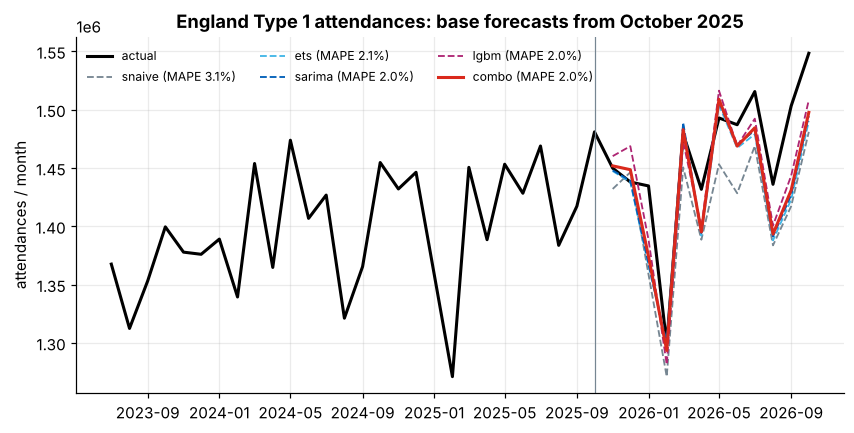

In [2]:
origin = pd.Timestamp("2025-10-01")
train, actual = y.loc[:origin], y.loc["2025-11":"2026-10", "England"]
post = train.loc["2021-07":]  # the COVID treatment that wins for attendances (section 2)
fcs = {}
for m in ["snaive", "ets", "sarima", "lgbm"]:
    fc, _ = base_forecast(post, 12, m, H.levels)
    fcs[m] = fc["England"]
fcs["combo"] = (fcs["ets"] + fcs["sarima"] + fcs["lgbm"]) / 3

fig, ax = plt.subplots()
ax.plot(y.loc["2023-07":, "England"], color="black", lw=2, label="actual")
for (m, f), c in zip(fcs.items(), [viz.NHS_GREY, viz.NHS_LIGHT, viz.NHS_BLUE, "#AE2573", viz.NHS_RED]):
    ape = np.mean(np.abs(f.to_numpy() - actual.to_numpy()) / actual.to_numpy())
    ax.plot(f.index, f, color=c, lw=2 if m == "combo" else 1.2, ls="-" if m == "combo" else "--", label=f"{m} (MAPE {ape:.1%})")
ax.axvline(origin, color=viz.NHS_GREY, lw=0.8)
ax.set_title("England Type 1 attendances: base forecasts from October 2025")
ax.set_ylabel("attendances / month")
ax.legend(ncol=3, fontsize=8)
viz.save(fig, "03_one_origin")

One origin is one sample, and one series is one level. The backtest repeats this at 9 origins for all 164 series.

## 2. Backtest results (MASE: below 1 beats seasonal naive)

In [3]:
summ = pd.read_csv(RESULTS / "backtest_summary_attendances.csv")
piv = summ.pivot_table(index=["covid", "model", "recon"], columns="level", values="MASE")[LEVELS]
piv["Average"] = piv.mean(axis=1)
piv.sort_values("Average").head(10).round(3)

level                      England  Region    ICB  Trust  Average
covid  model  recon                                              
post   combo  mint_shrink    0.396   0.459  0.613  0.662    0.532
              bu             0.420   0.479  0.619  0.665    0.546
              wls_struct     0.421   0.473  0.624  0.671    0.548
              base           0.441   0.478  0.627  0.665    0.553
impute ets    mint_shrink    0.407   0.478  0.653  0.699    0.559
       sarima bu             0.405   0.476  0.662  0.709    0.563
post   combo  ols            0.436   0.489  0.644  0.689    0.565
impute sarima wls_struct     0.414   0.485  0.679  0.720    0.575
              mint_shrink    0.436   0.494  0.679  0.717    0.581
              base           0.428   0.505  0.684  0.709    0.582

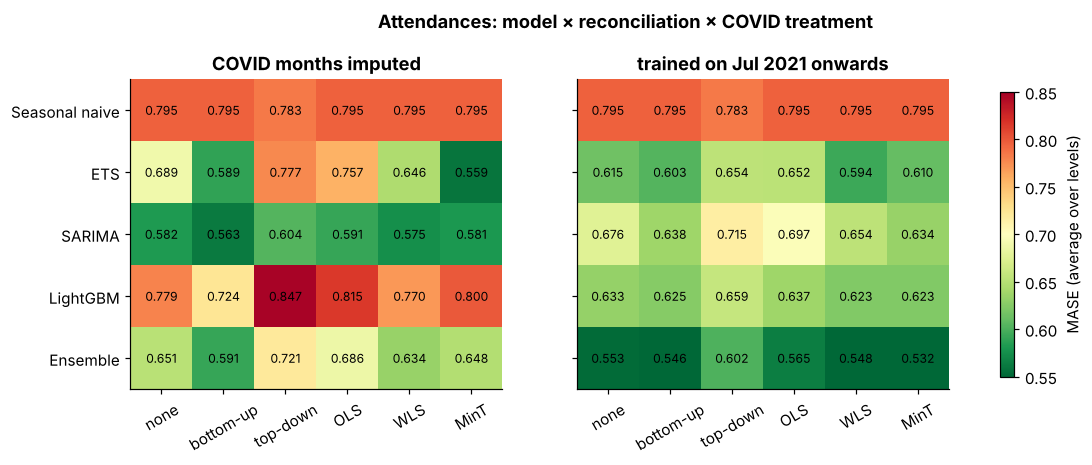

In [4]:
names = {"snaive": "Seasonal naive", "ets": "ETS", "sarima": "SARIMA", "lgbm": "LightGBM", "combo": "Ensemble"}
recon_names = {"base": "none", "bu": "bottom-up", "td": "top-down", "ols": "OLS", "wls_struct": "WLS", "mint_shrink": "MinT"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, covid in zip(axes, ["impute", "post"]):
    m = summ[summ.covid == covid].groupby(["model", "recon"]).MASE.mean().unstack()
    m = m.loc[list(names), list(recon_names)]
    im = ax.imshow(m.values, cmap="RdYlGn_r", vmin=0.55, vmax=0.85)
    ax.set_xticks(range(6), [recon_names[c] for c in m.columns], rotation=30)
    ax.set_yticks(range(5), [names[i] for i in m.index])
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.text(j, i, f"{m.values[i, j]:.3f}", ha="center", va="center", fontsize=8)
    ax.set_title({"impute": "COVID months imputed", "post": "trained on Jul 2021 onwards"}[covid])
    ax.grid(False)
fig.colorbar(im, ax=axes, shrink=0.8, label="MASE (average over levels)")
fig.suptitle("Attendances: model × reconciliation × COVID treatment", fontweight="bold")
viz.save(fig, "03_backtest_heatmap")

## 3. The same table for emergency admissions

In [5]:
summ_a = pd.read_csv(RESULTS / "backtest_summary_emergency_admissions.csv")
pa = summ_a.pivot_table(index=["covid", "model", "recon"], columns="level", values="MASE")[LEVELS]
pa["Average"] = pa.mean(axis=1)
pa.sort_values("Average").head(6).round(3)

level                     England  Region    ICB  Trust  Average
covid  model recon                                              
impute combo mint_shrink    0.377   0.522  0.752  0.882    0.633
             bu             0.398   0.533  0.763  0.885    0.645
       lgbm  mint_shrink    0.394   0.550  0.761  0.891    0.649
             bu             0.408   0.546  0.763  0.892    0.652
       combo wls_struct     0.403   0.544  0.771  0.901    0.655
             base           0.415   0.555  0.768  0.885    0.656

## 4. Accuracy by horizon for the winning configuration

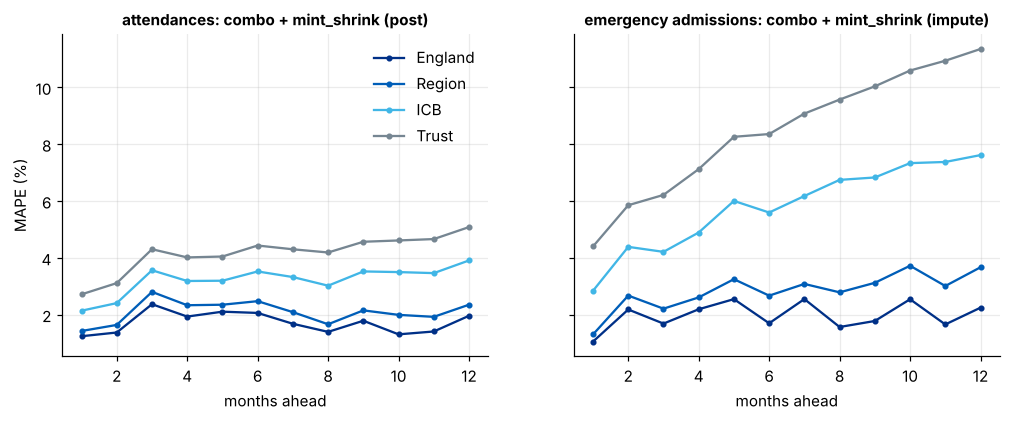

In [6]:
from nhsae.forecast import best_config  # noqa: E402

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, measure in zip(axes, ["attendances", "emergency_admissions"]):
    model, recon, covid = best_config(measure)
    hz = pd.read_csv(RESULTS / f"backtest_by_horizon_{measure}.csv")
    hz = hz[(hz.model == model) & (hz.recon == recon) & (hz.covid == covid)]
    for lvl in LEVELS:
        d = hz[hz.level == lvl]
        ax.plot(d.h, 100 * d.MAPE, marker="o", ms=3, color=viz.LEVEL_COLOURS[lvl], label=lvl)
    ax.set_title(f"{measure.replace('_', ' ')}: {model} + {recon} ({covid})", fontsize=10)
    ax.set_xlabel("months ahead")
axes[0].set_ylabel("MAPE (%)")
axes[0].legend()
viz.save(fig, "03_horizon")